# IPO Listing Gain Prediction

**Notebook 2 of 5 - Exploratory Data Analysis (EDA)**

**Data:** clean file from notebook 1 - 634 mainboard IPOs, Jan 2010 to May 2026

**Target:** `target_gain_pct` = listing day open / offer price - 1, in %

## Questions

1. How do IPOs usually list? (target distribution)
2. Does it change year to year?
3. How strong is subscription as a signal, and which investor category matters most?
4. Does issue size matter?
5. Are the unverified targets (Kaggle only) different from the verified ones?

In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from useful_func import missing_info

sns.set_style("darkgrid")
pd.set_option("display.float_format", "{:.2f}".format)
fig_dir = "../reports/figures/"

In [2]:
# read dataset
df = pd.read_csv("../data/interim/ipos_verified.csv", parse_dates=["listing_date"])
df = df[df["exclude_reason"].isna()].copy()     # empty reason = keep
df["year"] = df["listing_date"].dt.year
df.shape

(634, 31)

In [3]:
cols = ["issue_size_cr", "offer_price", "sub_qib", "sub_hni", "sub_rii", "sub_total", "target_gain_pct"]
df[["listing_date", "ipo_name"] + cols].head()

,listing_date,ipo_name,issue_size_cr,offer_price,sub_qib,sub_hni,sub_rii,sub_total,target_gain_pct
0,2010-01-04,JSW Energy Limited,2700.00,100.00,2.88,0.15,0.40,1.68,6.00
1,2010-01-05,Godrej Properties Limited,468.85,490.00,7.45,0.41,0.38,4.00,-3.01
2,2010-01-06,D B Corp Limited,384.22,212.00,68.52,26.17,3.42,39.54,19.81
3,2010-01-11,MBL Infrastructure Limited,102.60,180.00,3.35,2.65,0.40,1.97,2.78
4,2010-01-29,Birla Shloka Edutech Limited,34.78,50.00,0.00,5.45,1.76,1.43,-2.00


In [4]:
missing_info(df[cols])

,column_name,num_missing,missing%


In [5]:
df[cols].describe()

,issue_size_cr,offer_price,sub_qib,sub_hni,sub_rii,sub_total,target_gain_pct
count,634.00,634.00,634.00,634.00,634.00,634.00,634.00
mean,1368.07,363.94,49.84,72.90,16.31,37.95,16.80
std,2544.43,329.04,67.03,131.81,32.80,53.41,30.91
min,23.00,10.00,0.00,0.02,0.03,0.11,-39.63
25%,257.49,127.25,2.67,1.84,1.60,2.25,-0.05
50%,582.62,256.00,14.45,13.97,5.21,12.16,6.59
75%,1208.41,489.25,80.30,80.61,15.05,59.03,23.87
max,27858.80,2165.00,420.57,958.07,374.81,326.49,249.69


## Step 1: Target - Listing Day Gain

**What we do:** Look at the summary numbers and the distribution of the listing gain.

**Why we do it:** The shape of the target decides which metric makes sense and what kind of output is useful.

In [6]:
g = df["target_gain_pct"]
print("median gain -:", round(g.median(), 1))
print("mean gain -:", round(g.mean(), 1))
print("skew -:", round(g.skew(), 2))
print("listed below offer price -:", round((g < 0).mean() * 100, 1), "%")
print("listed flat (0%) -:", round((g == 0).mean() * 100, 1), "%")
print("gain above 15% -:", round((g > 15).mean() * 100, 1), "%")
print("gain above 50% -:", round((g > 50).mean() * 100, 1), "%")

median gain -: 6.6
mean gain -: 16.8
skew -: 2.51
listed below offer price -: 25.2 %
listed flat (0%) -: 6.3 %
gain above 15% -: 34.2 %
gain above 50% -: 11.5 %


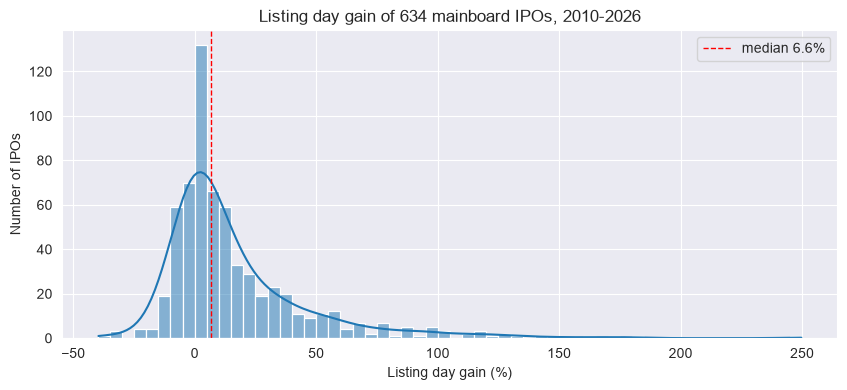

In [7]:
plt.figure(figsize=(10, 4))
sns.histplot(g, bins=np.arange(-40, 255, 5), kde=True)
plt.axvline(g.median(), color="red", ls="--", lw=1, label=f"median {g.median():.1f}%")
plt.title(f"Listing day gain of {len(df)} mainboard IPOs, 2010-2026")
plt.xlabel("Listing day gain (%)")
plt.ylabel("Number of IPOs")
plt.legend()
plt.savefig(fig_dir + "01_gain_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

**Observations:**
- median gain **6.6%**, mean gain **16.8%** - the mean is pulled up by a long right tail (skew **2.5**)
- **25%** of IPOs list below the offer price, about **6%** list flat
- **11.5%** gain more than 50%

**What it means for modelling:** MAE is a better main metric than RMSE (a few 200% IPOs would dominate RMSE),
and predicting a **range** along with a single number will be useful.

## Step 2: Year Wise Trend

**What we do:** Number of IPOs and median gain for each year.

**Why we do it:** To see if the IPO market behaves the same over time.

In [8]:
by_year = df.groupby("year").agg(ipos=("ipo_id", "count"),
                                 median_gain=("target_gain_pct", "median"),
                                 pct_loss=("target_gain_pct", lambda s: (s < 0).mean() * 100)).reset_index()
by_year

,year,ipos,median_gain,pct_loss
0,2010,74,5.37,21.62
1,2011,39,1.23,35.90
2,2012,11,1.45,36.36
3,2013,4,4.90,25.00
4,2014,6,16.94,33.33
5,2015,19,2.38,36.84
6,2016,27,9.59,25.93
7,2017,36,5.95,22.22
8,2018,24,1.35,45.83
9,2019,16,6.93,31.25


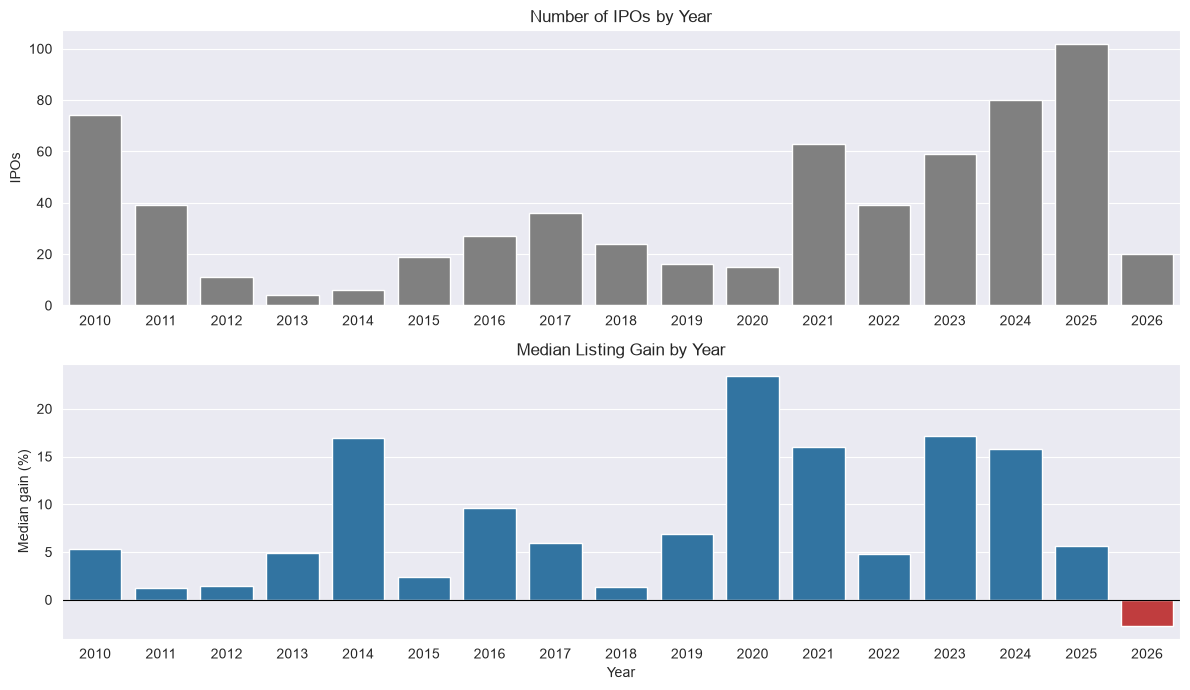

In [9]:
plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
sns.barplot(data=by_year, x="year", y="ipos", color="grey")
plt.title("Number of IPOs by Year")
plt.xlabel("")
plt.ylabel("IPOs")

plt.subplot(2, 1, 2)
sns.barplot(data=by_year, x="year", y="median_gain",
            palette=["tab:blue" if v >= 0 else "tab:red" for v in by_year["median_gain"]],
            hue="year", legend=False)
plt.axhline(0, color="black", lw=0.8)
plt.title("Median Listing Gain by Year")
plt.xlabel("Year")
plt.ylabel("Median gain (%)")

plt.tight_layout()
plt.savefig(fig_dir + "02_by_year.png", dpi=120, bbox_inches="tight")
plt.show()

**Observations:**
- IPOs come in waves - only **4** IPOs in 2013, **102** in 2025
- median gain swings from **-2.8%** (2026) to **23.4%** (2020)

**What it means for modelling:** a random `train_test_split` is **not correct** here - it would train on 2025
IPOs and test on 2019 ones. The split has to be **by time**: train on older years, test on newer ones.

## Step 3: Subscription

**What we do:** Group IPOs into total subscription buckets and compare their listing gain. Then check which
investor category (QIB / HNI / Retail) is most related to the gain.

**Why we do it:** Subscription is the number every IPO investor looks at - need to see how strong it really is.

In [10]:
edges = [0, 1, 3, 10, 30, 100, 1e5]
labels = ["<1x", "1-3x", "3-10x", "10-30x", "30-100x", "100x+"]
df["sub_bucket"] = pd.cut(df["sub_total"], edges, labels=labels)

by_bucket = df.groupby("sub_bucket", observed=True)["target_gain_pct"].agg(
    ipos="count", median="median", mean="mean",
    p25=lambda s: s.quantile(0.25), p75=lambda s: s.quantile(0.75),
    pct_positive=lambda s: (s > 0).mean() * 100)
by_bucket

,ipos,median,mean,p25,p75,pct_positive
sub_bucket,,,,,,
<1x,26,0.00,0.58,-5.47,3.01,38.46
1-3x,177,0.00,-1.10,-5.98,2.38,41.24
3-10x,104,3.88,3.54,-2.03,9.27,61.54
10-30x,90,9.92,11.02,0.00,18.23,70.00
30-100x,164,23.26,29.06,9.85,43.09,92.07
100x+,73,56.56,64.47,33.33,87.50,100.00


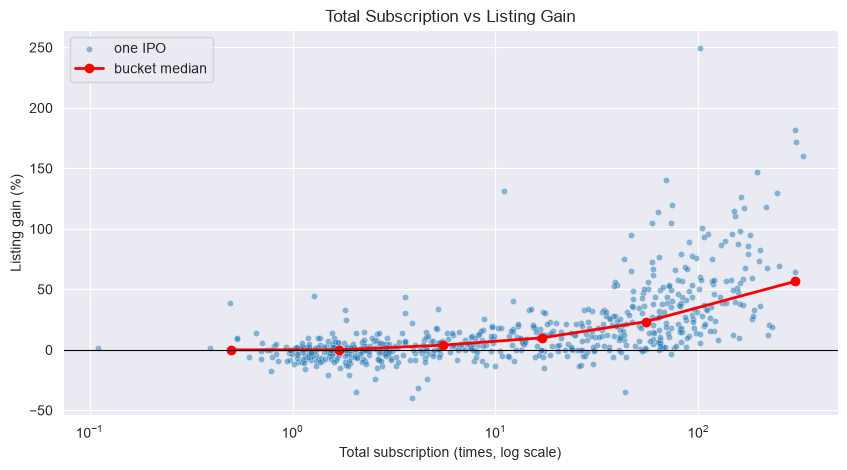

In [11]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="sub_total", y="target_gain_pct", alpha=0.5, s=20, label="one IPO")
mid = [0.5, 1.7, 5.5, 17, 55, 300]   # rough middle of each bucket on log scale
plt.plot(mid, by_bucket["median"], "o-", color="red", lw=2, label="bucket median")
plt.xscale("log")
plt.axhline(0, color="black", lw=0.8)
plt.title("Total Subscription vs Listing Gain")
plt.xlabel("Total subscription (times, log scale)")
plt.ylabel("Listing gain (%)")
plt.legend()
plt.savefig(fig_dir + "03_subscription_vs_gain.png", dpi=120, bbox_inches="tight")
plt.show()

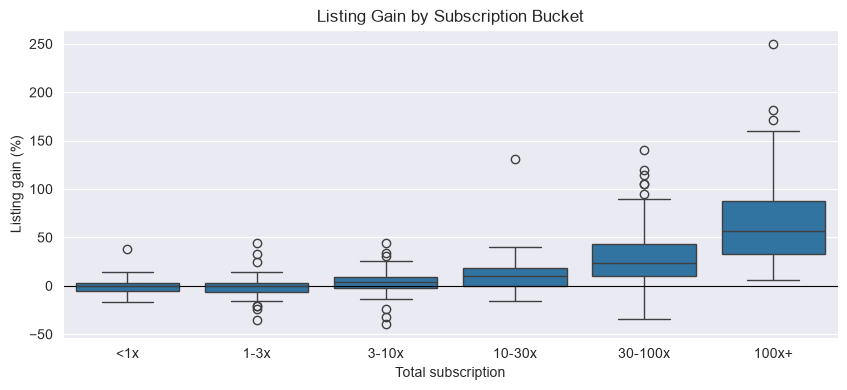

In [12]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="sub_bucket", y="target_gain_pct")
plt.axhline(0, color="black", lw=0.8)
plt.title("Listing Gain by Subscription Bucket")
plt.xlabel("Total subscription")
plt.ylabel("Listing gain (%)")
plt.show()

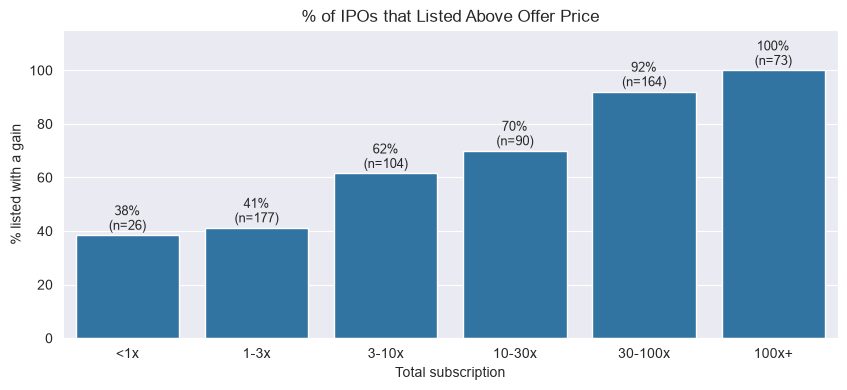

In [13]:
hit = by_bucket.reset_index()

plt.figure(figsize=(10, 4))
sns.barplot(data=hit, x="sub_bucket", y="pct_positive", color="tab:blue")
for i, (p, n) in enumerate(zip(hit["pct_positive"], hit["ipos"])):
    plt.text(i, p + 2, f"{p:.0f}%\n(n={n})", ha="center", fontsize=9)
plt.ylim(0, 115)
plt.title("% of IPOs that Listed Above Offer Price")
plt.xlabel("Total subscription")
plt.ylabel("% listed with a gain")
plt.savefig(fig_dir + "04_hit_rate_by_subscription.png", dpi=120, bbox_inches="tight")
plt.show()

**Observations:**

| Total subscription | IPOs | Median gain | % listed with a gain |
|---|---|---|---|
| < 1x | 26 | 0.0% | 38% |
| 1 - 3x | 177 | 0.0% | 41% |
| 3 - 10x | 104 | 3.9% | 62% |
| 10 - 30x | 90 | 9.9% | 70% |
| 30 - 100x | 164 | 23.3% | 92% |
| 100x+ | 73 | 56.6% | 100% |

- below 3x, less than half list with a gain and the median IPO lists flat
- above 30x, more than 9 in 10 list with a gain

**What it means for modelling:**
- the popular "apply only if 30x+ subscribed" rule is real -> the **bucket median** becomes a baseline the
  model has to beat
- subscription goes from 0.5x to 1000x+ -> use **log** of subscription

In [14]:
# which investor category matters most? (spearman because of the outliers)
df[["sub_qib", "sub_hni", "sub_rii", "sub_total", "issue_size_cr", "offer_price", "target_gain_pct"]].corr(
    method="spearman")["target_gain_pct"].sort_values(ascending=False)

target_gain_pct    1.00
sub_total          0.71
sub_hni            0.67
sub_qib            0.64
sub_rii            0.58
offer_price        0.03
issue_size_cr     -0.02
Name: target_gain_pct, dtype: float64

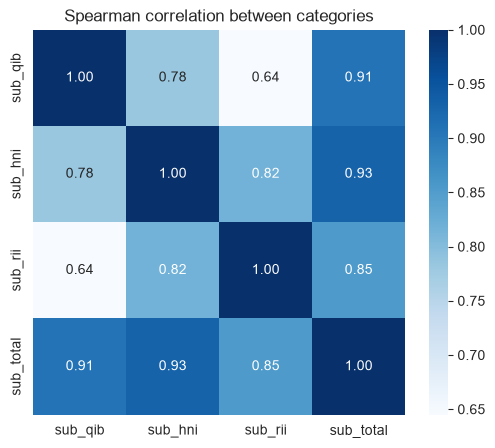

In [15]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[["sub_qib", "sub_hni", "sub_rii", "sub_total"]].corr(method="spearman"), annot=True,
            fmt=".2f", cmap="Blues")
plt.title("Spearman correlation between categories")
plt.show()

**Observations:**
- Spearman correlation with gain: total **0.71**, HNI **0.67**, QIB **0.64**, retail **0.58**
- issue size and offer price: about **0**
- the 4 subscription columns are strongly correlated with each other (**0.64 - 0.93**) -> multicollinearity

**What it means for modelling:** tree models handle correlated features fine; for the linear model use
**Ridge** (regularisation) instead of plain linear regression.

## Step 4: Issue Size

**What we do:** Split IPOs into 4 equal groups by issue size and compare median gain.

**Why we do it:** Big issues might behave differently (more institutional money, less retail frenzy).

In [16]:
df["size_bucket"] = pd.qcut(df["issue_size_cr"], 4, labels=["smallest 25%", "small-mid", "mid-large", "largest 25%"])
df.groupby("size_bucket", observed=True).agg(min_size=("issue_size_cr", "min"), max_size=("issue_size_cr", "max"),
                                             ipos=("ipo_id", "count"), median_gain=("target_gain_pct", "median"),
                                             median_sub=("sub_total", "median"))

,min_size,max_size,ipos,median_gain,median_sub
size_bucket,,,,,
smallest 25%,23.00,256.64,159,6.29,6.32
small-mid,260.04,582.56,158,7.17,21.00
mid-large,582.69,1204.29,158,8.36,20.33
largest 25%,1209.78,27858.80,159,5.30,7.77


**Observation:** Median gain is between **5.3%** and **8.4%** in all 4 groups - not much difference on its own.

**Decision:** Still keep it (log scale) - the model can combine it with subscription.

## Step 5: Verified vs Unverified Target

**What we do:** Compare the 499 verified targets with the 135 Kaggle-only ones.

**Why we do it:** To make sure the unverified rows are not a biased or broken part of the data.

In [17]:
df.groupby("target_source")["target_gain_pct"].describe()

,count,mean,std,min,25%,50%,75%,max
target_source,,,,,,,,
kaggle_unverified,135.00,10.50,22.95,-31.73,-0.67,5.22,14.41,171.43
nse_open_yahoo,499.00,18.51,32.55,-39.63,0.00,6.88,27.88,249.69


In [18]:
df.groupby("target_source")["year"].agg(["min", "median", "max"])

,min,median,max
target_source,,,
kaggle_unverified,2010,2011.00,2025
nse_open_yahoo,2010,2022.00,2026


**Observations:**
- unverified rows are mostly old IPOs (median year **2011** vs **2022**) - older companies are more likely to be
  delisted or merged, so they are not on NSE's list to check against
- their lower gains (median **5.2%** vs **6.9%**) match how 2010-2012 IPOs did in general (median 1-5% in
  those years)

**Conclusion:** the difference comes from the era, not from bad data - keeping them.

## Summary - What EDA Tells the Model

| Finding | Decision for modelling |
|---|---|
| target is right skewed with a long tail | MAE as main metric, also predict an 80% range |
| IPO market moves in waves | time based split, never random |
| subscription is the strongest signal, 0.5x - 1000x | log1p of subscription |
| total / HNI / QIB > retail, categories correlated | keep all 4 + QIB vs retail; Ridge for linear model |
| "30x+" rule works | bucket median as baseline |
| market mood not checked yet | next notebook |

**Next notebook:** `03_feature_engineering.ipynb`